# Validación

#### Dependencias

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, f1_score
from xgboost import plot_importance

#### Lectura

In [2]:
X_train = pd.read_csv("../data/processed/X_train.csv")
X_test = pd.read_csv("../data/processed/X_test.csv")
y_train = pd.read_csv("../data/processed/y_train.csv")["smoking"]
y_test = pd.read_csv("../data/processed/y_test.csv")["smoking"]

modelo = joblib.load("../models/modelo_xgb.joblib") # el XGBoost que guardamos en el notebook 04

#### Probabilidades predichas

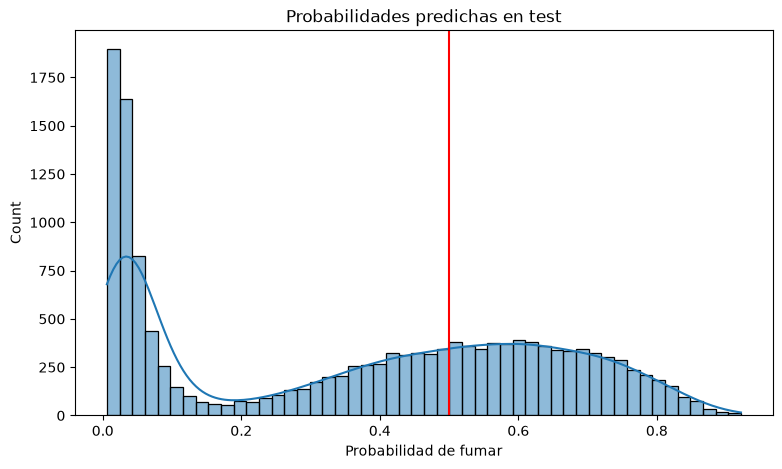

In [3]:
test_proba = modelo.predict_proba(X_test)[:, 1] # probabilidad de que cada persona fume

plt.figure(figsize=(9,5))
sns.histplot(test_proba, bins=50, kde=True)
plt.axvline(0.5, color="red")
plt.title("Probabilidades predichas en test")
plt.xlabel("Probabilidad de fumar")
plt.show()

El histograma tiene dos grupos: muchas personas con probabilidad cercana a 0, donde el modelo está muy seguro de que no fuman (seguramente las mujeres), y una loma entre 0,3 y 0,9, donde duda más (seguramente los hombres). El umbral de 0,5 cae justo en medio de esa loma.

#### Umbral de corte

In [4]:
train_proba_cv = cross_val_predict(modelo, X_train, y_train, cv=5, method="predict_proba")[:, 1]

In [5]:
for umbral in [0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    pred = (train_proba_cv >= umbral).astype(int)
    print(f"Umbral {umbral}: f1 {f1_score(y_train, pred):.3f}")

Umbral 0.35: f1 0.718
Umbral 0.4: f1 0.718
Umbral 0.45: f1 0.712
Umbral 0.5: f1 0.692
Umbral 0.55: f1 0.662
Umbral 0.6: f1 0.606


In [6]:
for umbral in np.arange(0.30, 0.46, 0.01):
    pred = (train_proba_cv >= umbral).astype(int)
    print(f"Umbral {umbral:.2f}: f1 {f1_score(y_train, pred):.3f}")

Umbral 0.30: f1 0.713
Umbral 0.31: f1 0.714
Umbral 0.32: f1 0.715
Umbral 0.33: f1 0.716
Umbral 0.34: f1 0.717
Umbral 0.35: f1 0.718
Umbral 0.36: f1 0.718
Umbral 0.37: f1 0.718
Umbral 0.38: f1 0.719
Umbral 0.39: f1 0.718
Umbral 0.40: f1 0.718
Umbral 0.41: f1 0.717
Umbral 0.42: f1 0.716
Umbral 0.43: f1 0.715
Umbral 0.44: f1 0.713
Umbral 0.45: f1 0.712
Umbral 0.46: f1 0.710


El mejor umbral es 0,38, con un f1 de 0,719. Entre 0,35 y 0,40 el f1 casi no cambia, así que el resultado es estable. El umbral se eligió con validación cruzada sobre train, sin usar test.

In [7]:
umbral = 0.38

test_pred_05 = (test_proba >= 0.5).astype(int)
test_pred_umbral = (test_proba >= umbral).astype(int)

print("Test con umbral 0,5")
print(classification_report(y_test, test_pred_05))
print("--------------------------------------------------------")
print(f"Test con umbral {umbral}")
print(classification_report(y_test, test_pred_umbral))

Test con umbral 0,5
              precision    recall  f1-score   support

           0       0.83      0.79      0.81      9501
           1       0.67      0.72      0.70      5499

    accuracy                           0.77     15000
   macro avg       0.75      0.76      0.75     15000
weighted avg       0.77      0.77      0.77     15000

--------------------------------------------------------
Test con umbral 0.38
              precision    recall  f1-score   support

           0       0.91      0.67      0.77      9501
           1       0.61      0.88      0.72      5499

    accuracy                           0.75     15000
   macro avg       0.76      0.78      0.75     15000
weighted avg       0.80      0.75      0.75     15000



In [8]:
joblib.dump(umbral, "../models/umbral.joblib") # para usar el mismo umbral en la predicción final

['../models/umbral.joblib']

Con el umbral 0,38, el f1 en test sube de 0,70 a 0,72. El modelo encuentra muchos más fumadores (recall de 0,72 a 0,88), a cambio de equivocarse un poco más al señalarlos (precision de 0,67 a 0,61). El accuracy baja un poco, pero el f1 de los fumadores mejora.

#### Importancia de variables

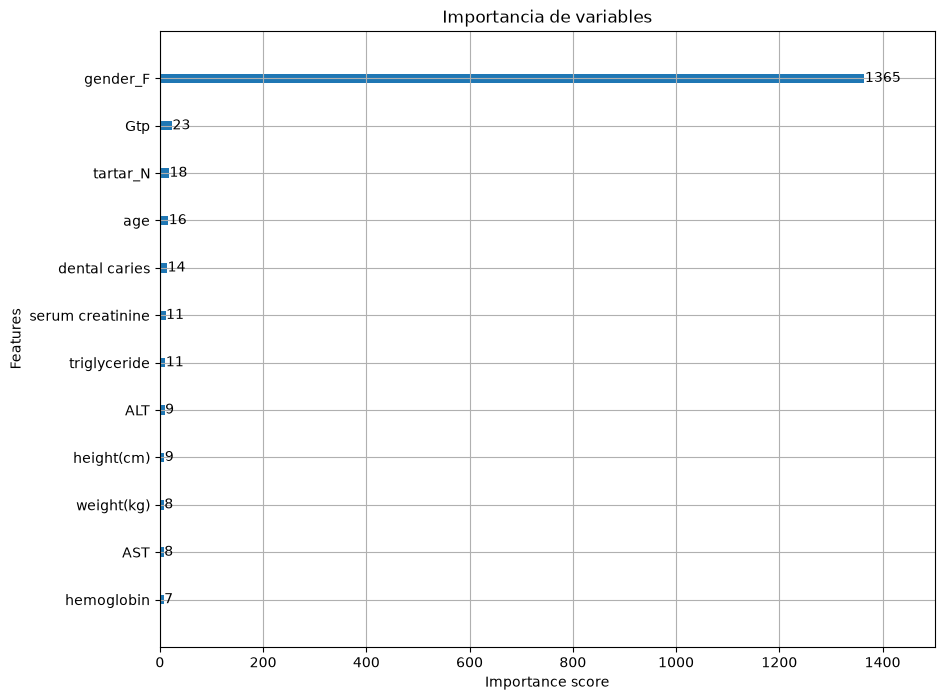

In [9]:
fig, ax = plt.subplots(figsize=(10,8))
plot_importance(modelo, ax=ax, max_num_features=12, importance_type="gain", values_format="{v:.0f}")
plt.title("Importancia de variables")
plt.show()

El género es la variable más importante del modelo: pesa unas 60 veces más que la segunda (Gtp, una enzima del hígado). La hemoglobina, la altura y el peso, que en el EDA parecían muy relacionadas con fumar, quedan al final de la lista. Esto confirma que parecían importantes porque reflejaban el género.